In [1]:
import sys
import os
import sklearn
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import scipy

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, RocCurveDisplay
from scipy.stats import kstest

import lightgbm as lgb
import kagglehub

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Seaborn version:", sns.__version__)
print("Joblib version:", joblib.__version__)
print("SciPy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("LightGBM version:", lgb.__version__)

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
NumPy version: 2.0.2
Pandas version: 2.2.2
Scikit-learn version: 1.6.1
Seaborn version: 0.13.2
Joblib version: 1.5.3
SciPy version: 1.16.3
Matplotlib version: 3.10.0
LightGBM version: 4.6.0


In [2]:
path = kagglehub.dataset_download("muhammadshahidazeem/customer-churn-dataset")

print("Path to dataset files:", path)

100%|██████████| 6.66M/6.66M [00:00<00:00, 94.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/muhammadshahidazeem/customer-churn-dataset/versions/1


In [3]:
!ls /root/.cache/kagglehub/datasets/muhammadshahidazeem/customer-churn-dataset/versions/1

customer_churn_dataset-testing-master.csv
customer_churn_dataset-training-master.csv


In [4]:
df = pd.read_csv(os.path.join(path, 'customer_churn_dataset-testing-master.csv'))
df.head()
df.info()
df.describe() #Получаем сводную статистику по каждому признаку

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


Num Index(['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')
Cat Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object')


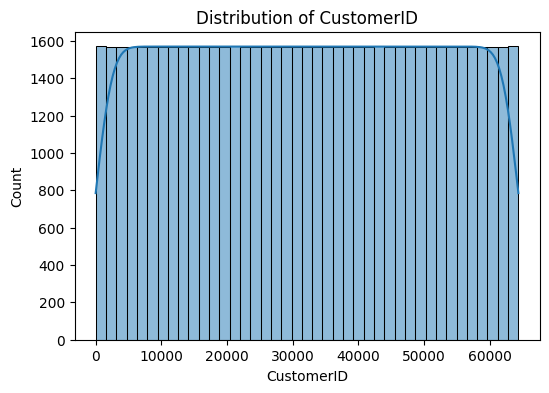

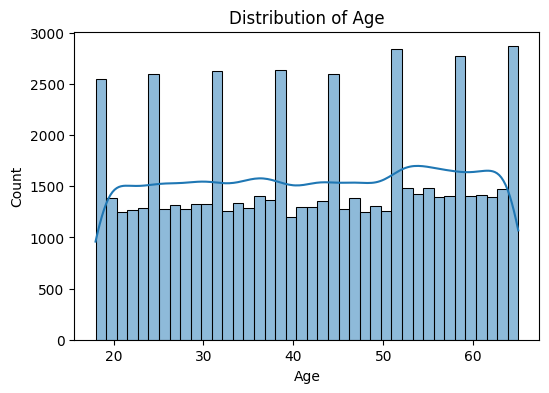

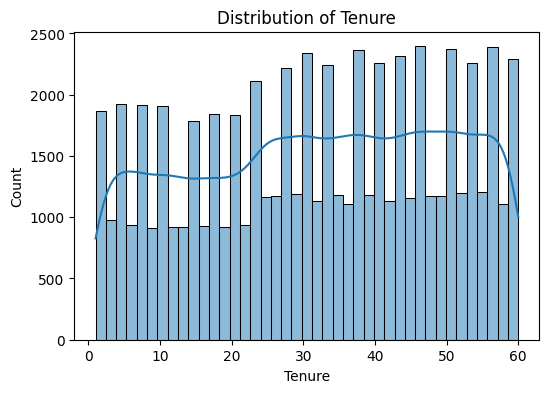

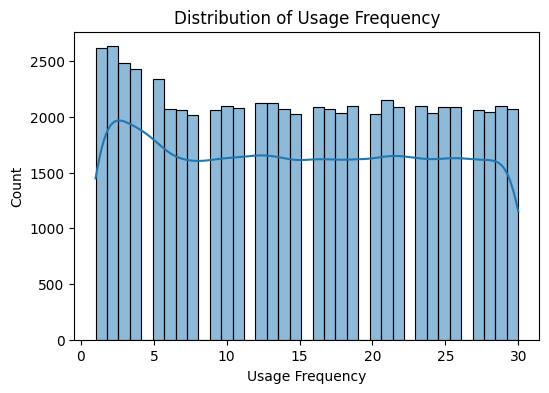

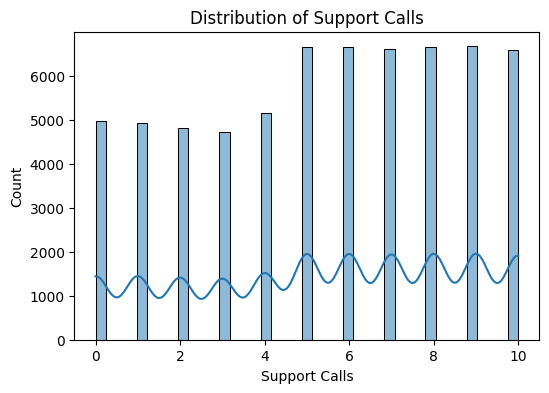

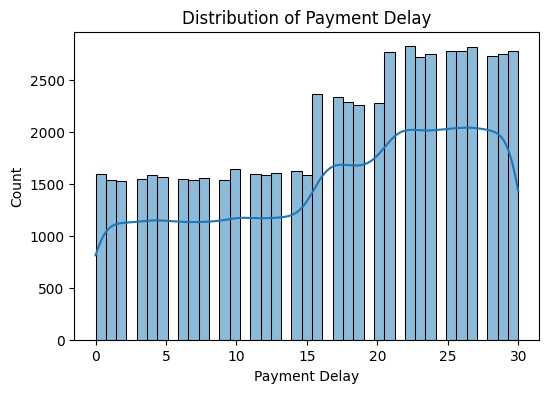

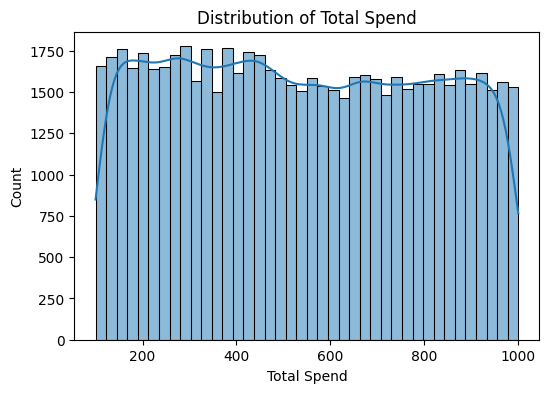

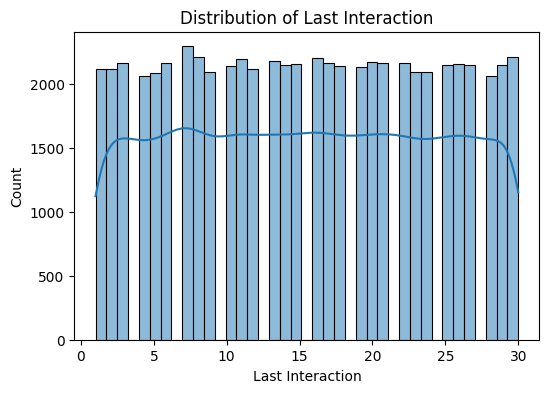

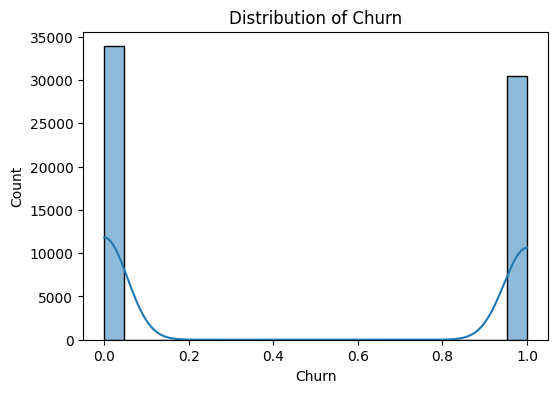

In [5]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns
print('Num', num_cols)
print('Cat', cat_cols)

for col in num_cols:
  plt.figure(figsize=(6,4))
  sns.histplot(df[col], kde=True)
  plt.title(f'Distribution of {col}')
  plt.show()

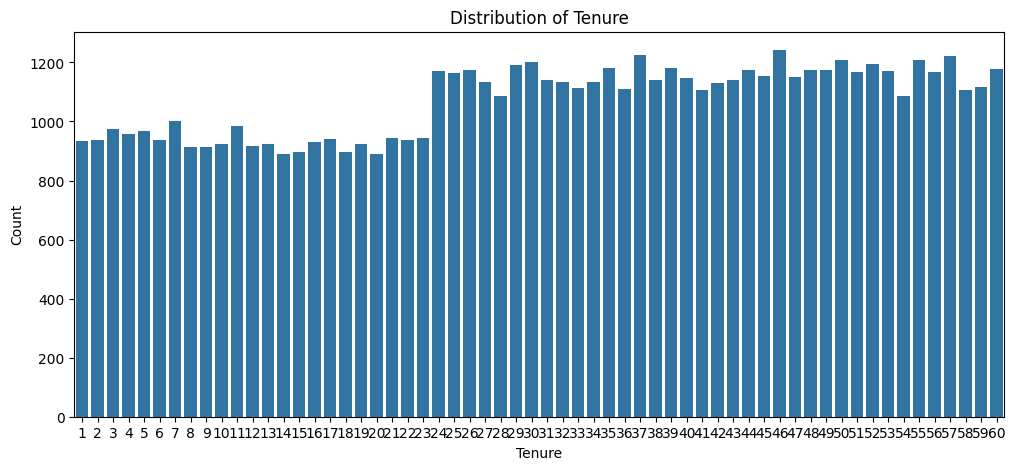

In [9]:
plt.figure(figsize=(12,5))

sns.countplot(
    x=df['Tenure']
)

plt.title('Distribution of Tenure')
plt.xlabel('Tenure')
plt.ylabel('Count')

plt.xticks(rotation=0)

plt.show()

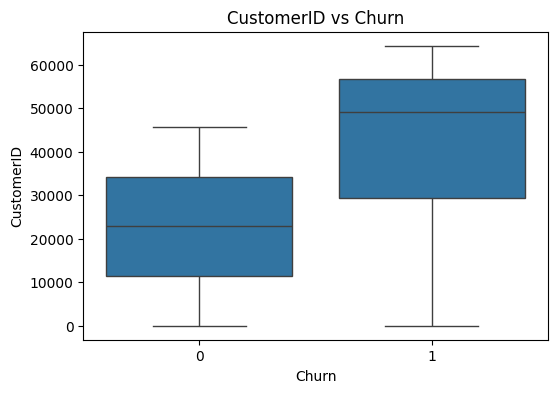

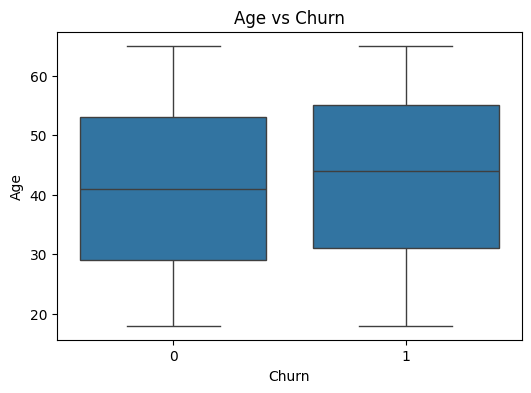

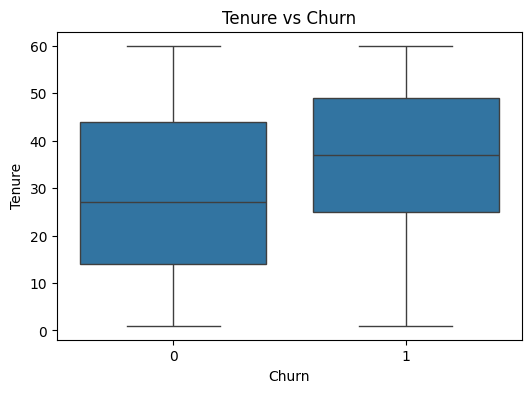

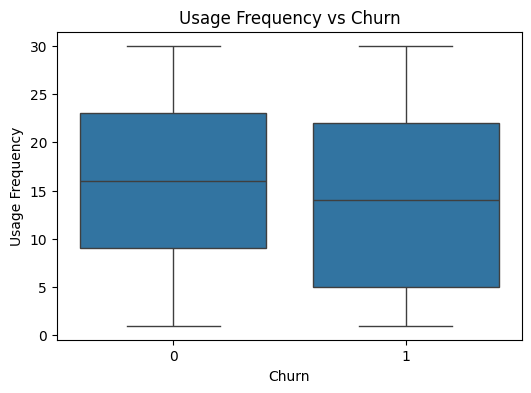

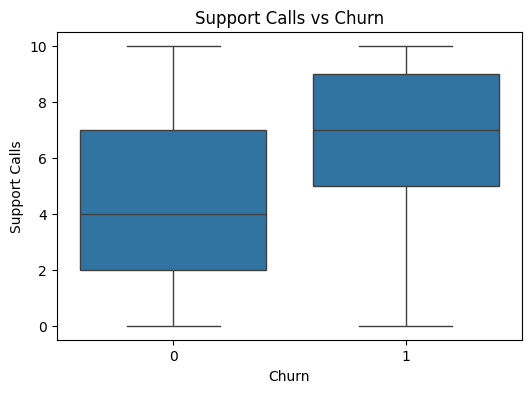

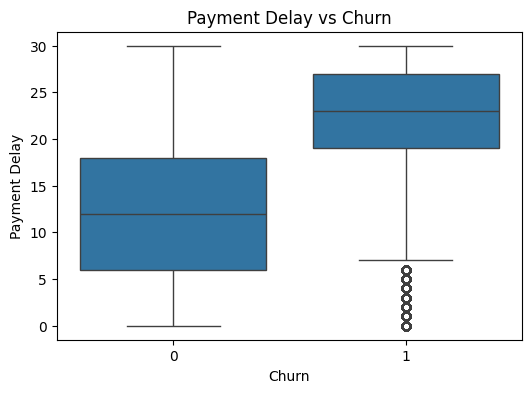

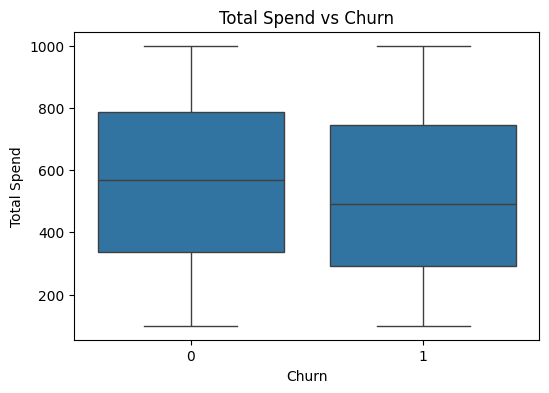

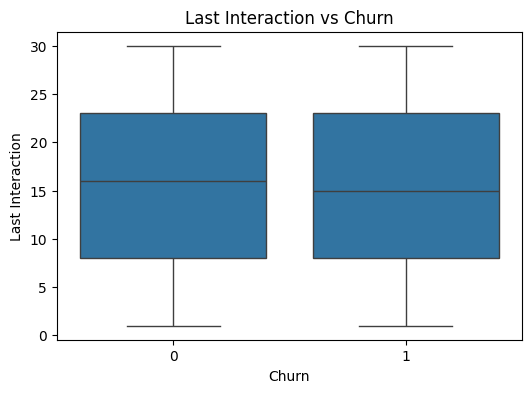

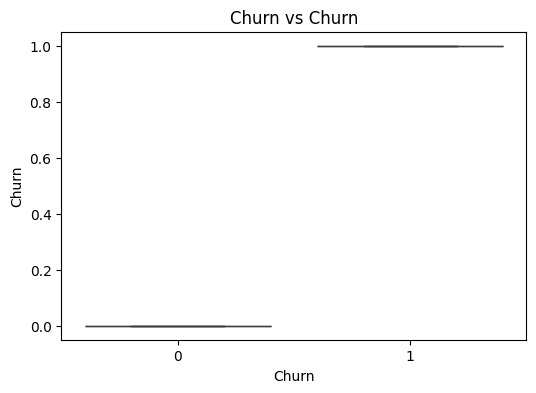

In [ ]:
for col in num_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x='Churn', y=col, data=df)
  plt.title(f'{col} vs Churn')
  plt.show() # Ящик с усами

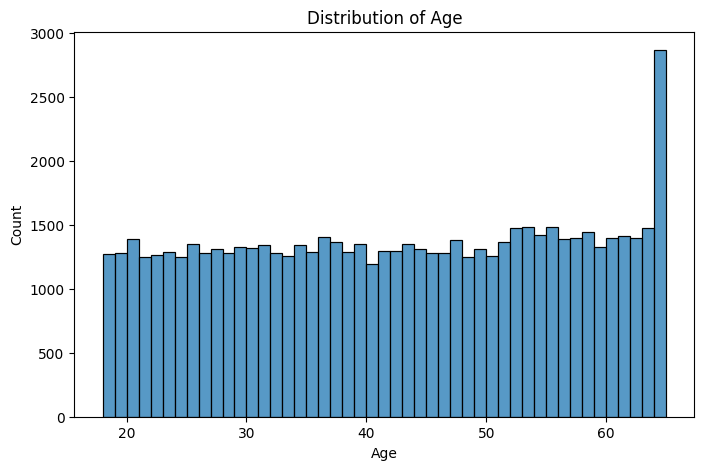

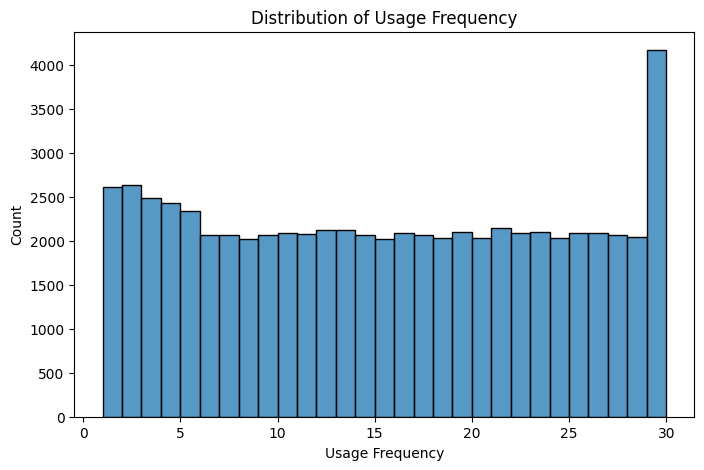

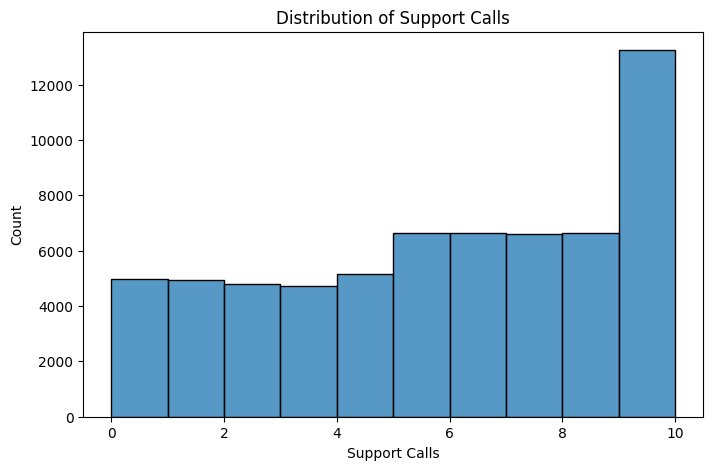

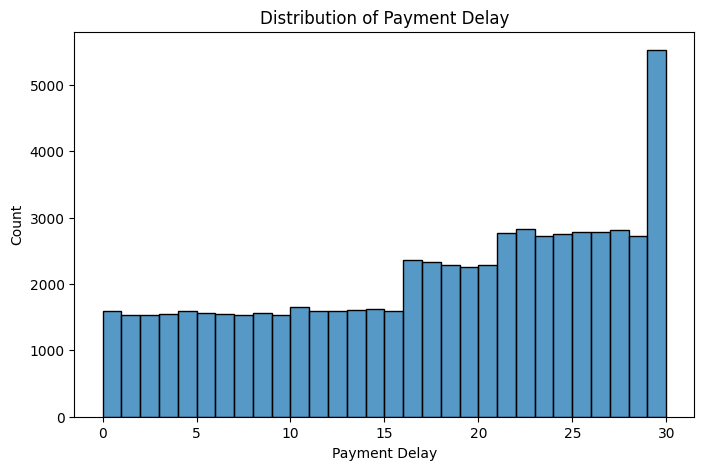

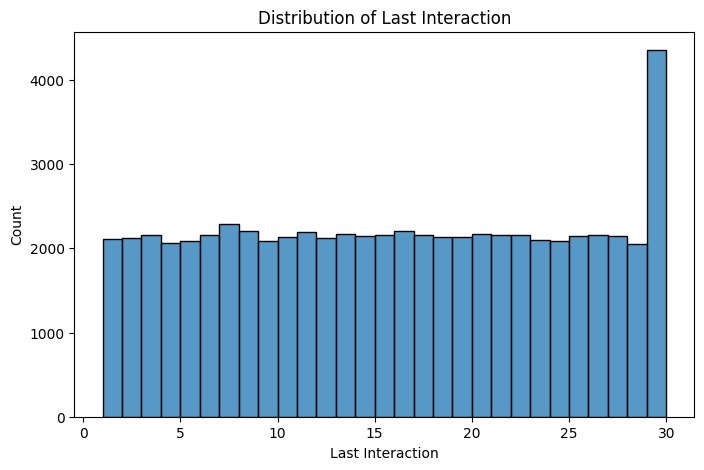

In [ ]:
# AGE
plt.figure(figsize=(8,5))

sns.histplot(
    df['Age'],
    binwidth=1,
    kde=False
)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()

# Usage Frequency
plt.figure(figsize=(8,5))

sns.histplot(
    df['Usage Frequency'],
    binwidth=1,
    kde=False
)

plt.title('Distribution of Usage Frequency')
plt.xlabel('Usage Frequency')
plt.ylabel('Count')

plt.show()

# Support Calls
plt.figure(figsize=(8,5))

sns.histplot(
    df['Support Calls'],
    binwidth=1,
    kde=False
)

plt.title('Distribution of Support Calls')
plt.xlabel('Support Calls')
plt.ylabel('Count')

plt.show()

# Payment Delay
plt.figure(figsize=(8,5))

sns.histplot(
    df['Payment Delay'],
    binwidth=1,
    kde=False
)

plt.title('Distribution of Payment Delay')
plt.xlabel('Payment Delay')
plt.ylabel('Count')

plt.show()

# Last Interaction
plt.figure(figsize=(8,5))

sns.histplot(
    df['Last Interaction'],
    binwidth=1,
    kde=False
)

plt.title('Distribution of Last Interaction')
plt.xlabel('Last Interaction')
plt.ylabel('Count')

plt.show()

In [ ]:
for col in [
    'Age',
    'Usage Frequency',
    'Support Calls',
    'Payment Delay',
    'Last Interaction'
]:
    print(f'\n{col}')
    print(df[col].value_counts().sort_index().tail(10))


Age
Age
56    1392
57    1401
58    1449
59    1330
60    1402
61    1414
62    1397
63    1473
64    1395
65    1474
Name: count, dtype: int64

Usage Frequency
Usage Frequency
21    2148
22    2093
23    2096
24    2033
25    2091
26    2089
27    2062
28    2040
29    2099
30    2071
Name: count, dtype: int64

Support Calls
Support Calls
1     4929
2     4812
3     4723
4     5148
5     6657
6     6639
7     6599
8     6649
9     6664
10    6587
Name: count, dtype: int64

Payment Delay
Payment Delay
21    2766
22    2821
23    2716
24    2748
25    2781
26    2781
27    2818
28    2726
29    2748
30    2774
Name: count, dtype: int64

Last Interaction
Last Interaction
21    2160
22    2159
23    2094
24    2091
25    2145
26    2153
27    2148
28    2056
29    2149
30    2206
Name: count, dtype: int64


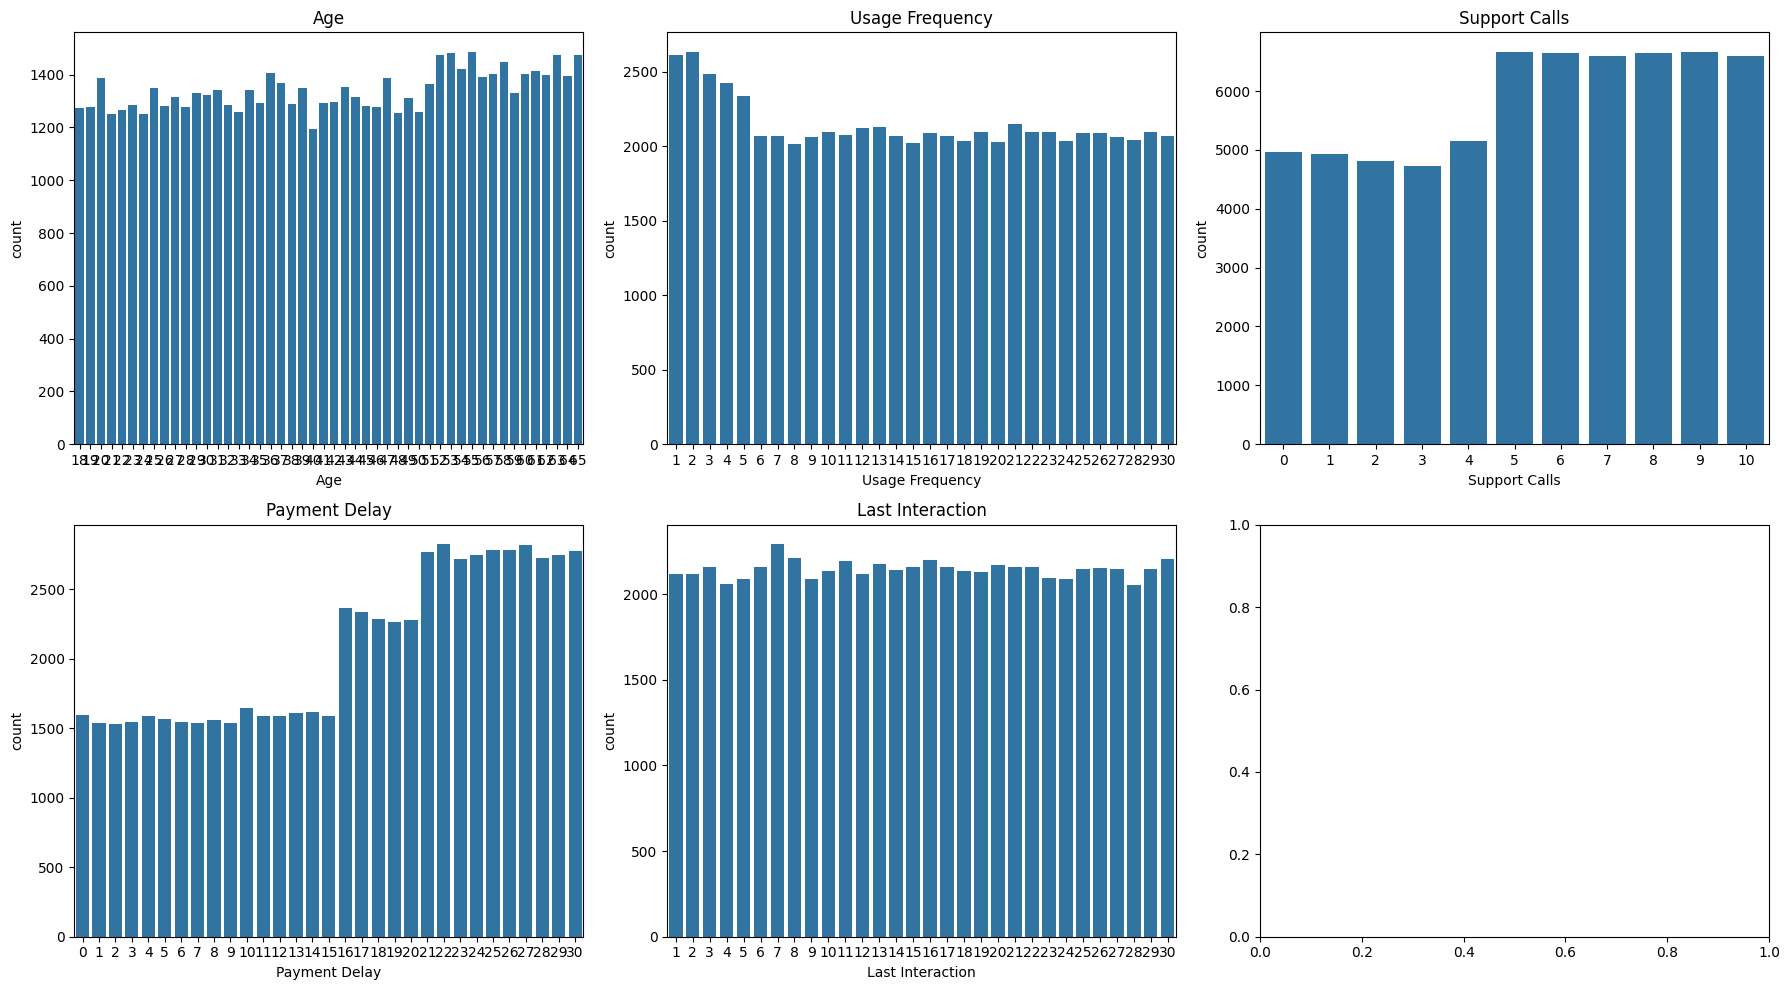

In [ ]:
features = [
    'Age',
    'Usage Frequency',
    'Support Calls',
    'Payment Delay',
    'Last Interaction'
]

fig, axes = plt.subplots(2, 3, figsize=(18,10))

axes = axes.flatten()

for i, col in enumerate(features):

    sns.countplot(
        x=col,
        data=df,
        ax=axes[i]
    )

    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [ ]:
#Критерий Колмагорова-Смирнова (KS)
from scipy.stats import kstest

for col in ['Age', 'Last Interaction']:

    x = df[col]

    x_scaled = (
        x - x.min()
    ) / (
        x.max() - x.min()
    )

    stat, p = kstest(x_scaled, 'uniform')

    print(f'\n{col}')
    print(f'KS statistic = {stat:.4f}')
    print(f'p-value = {p:.4f}')


Age
KS statistic = 0.0340
p-value = 0.0000

Last Interaction
KS statistic = 0.0343
p-value = 0.0000


p-value < 0.05 => H0 не отвергается

<Axes: xlabel='Usage Frequency', ylabel='Count'>

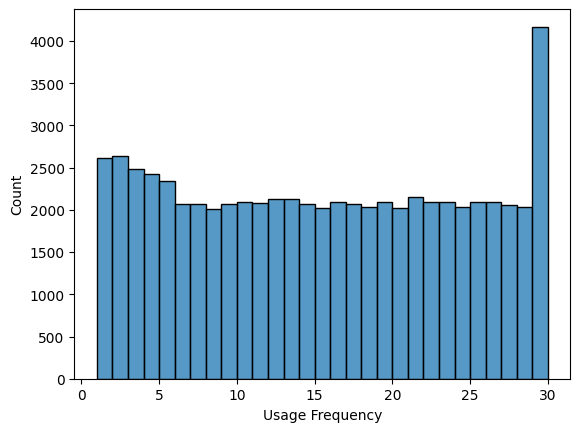

In [ ]:
sns.histplot(
    df['Usage Frequency'],
    binwidth=1,
    kde=False
)

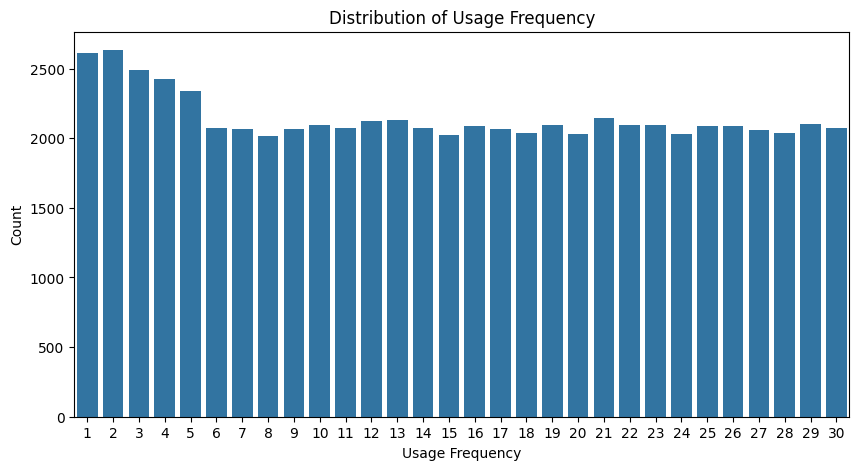

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    x='Usage Frequency',
    data=df
)

plt.title('Distribution of Usage Frequency')
plt.xlabel('Usage Frequency')
plt.ylabel('Count')

plt.show()

In [ ]:
df.groupby('Churn').mean(numeric_only=True)



,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,,
0,22846.794959,41.132700,28.826481,16.042915,4.500753,12.453086,560.541956,15.521944
1,42566.027121,42.902404,35.515200,14.010593,6.400617,22.334897,519.336143,15.473191


In [ ]:
df_model = df.drop(columns=['CustomerID'])

In [ ]:
features_important = ['Tenure', 'Support Calls', 'Payment Delay']
X = df_model[features_important]
y = df_model['Churn']

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

X_train = pd.get_dummies(X_train, drop_first=True)
X_val = pd.get_dummies(X_val, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_val = X_train.align(X_val, join='left', axis=1, fill_value=0)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [ ]:
def business_classifier(row):
    if row['Payment Delay'] > 20:
        return 1
    elif row['Support Calls'] > 6:
        return 1
    else:
        return 0

X_test_with_target = X_test.copy()
X_test_with_target['Churn'] = y_test
X_test_with_target['business_pred'] = X_test_with_target.apply(business_classifier, axis=1)

biz_accuracy = accuracy_score(X_test_with_target['Churn'], X_test_with_target['business_pred'])
biz_roc_auc = roc_auc_score(X_test_with_target['Churn'], X_test_with_target['business_pred'])

print("\n--- Business Rule Baseline ---")
print(f"Accuracy: {biz_accuracy:.4f}")
print(f"ROC-AUC:  {biz_roc_auc:.4f}")


--- Business Rule Baseline ---
Accuracy: 0.7118
ROC-AUC:  0.7198


In [ ]:
# LG + GridSearch
pipe_lr = Pipeline([

    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

param_grid_lr = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__max_iter': [100, 300, 700]
}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=5, scoring='roc_auc')
grid_lr.fit(X_train, y_train)

y_pred_lr = grid_lr.predict_proba(X_test)[:, 1]
roc_auc_lr = roc_auc_score(y_test, y_pred_lr)
print(f"Logistic Regression ROC-AUC: {roc_auc_lr:.4f} (Best params: {grid_lr.best_params_})")

Logistic Regression ROC-AUC: 0.8803 (Best params: {'model__C': 0.1, 'model__max_iter': 100})


In [ ]:
X_train.head()

,Tenure,Support Calls,Payment Delay
5871,7,0,27
40570,49,10,0
200,24,1,26
64037,27,9,24
13249,18,0,24


In [ ]:
grid_lr.best_estimator_['model'].coef_


array([[0.50097612, 0.8726592 , 1.66282068]])

In [ ]:
grid_lr.best_estimator_['model'].na

AttributeError: 'LogisticRegression' object has no attribute 'na'

In [ ]:
# Polynominal Logistic Regression
pipe_poly_lr = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=2000, C=grid_lr.best_params_['model__C']))
])

pipe_poly_lr.fit(X_train, y_train)
y_pred_poly_lr = pipe_poly_lr.predict_proba(X_test)[:, 1]
roc_auc_poly_lr = roc_auc_score(y_test, y_pred_poly_lr)
print(f"Polynomial LR ROC-AUC: {roc_auc_poly_lr:.4f}")

Polynomial LR ROC-AUC: 0.8937


In [ ]:
# Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict_proba(X_test)[:, 1]
roc_auc_rf = roc_auc_score(y_test, y_pred_rf)
print(f"Random Forest ROC-AUC: {roc_auc_rf:.4f}")

Random Forest ROC-AUC: 0.9069


In [ ]:
# KNN
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict_proba(X_test)[:, 1]
roc_auc_knn = roc_auc_score(y_test, y_pred_knn)
print(f"KNN ROC-AUC: {roc_auc_knn:.4f}")

KNN ROC-AUC: 0.9071


In [ ]:
# LGBM
lgbm_model = lgb.LGBMClassifier(random_state=42, verbose=-1)

param_grid_lgbm = {
    'n_estimators': [100, 300],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [20, 31]
}

grid_lgbm = GridSearchCV(lgbm_model, param_grid_lgbm, cv=3, scoring='roc_auc', n_jobs=-1)
grid_lgbm.fit(X_train, y_train)

y_pred_lgbm = grid_lgbm.predict_proba(X_test)[:, 1]
roc_auc_lgbm = roc_auc_score(y_test, y_pred_lgbm)
print(f"LightGBM ROC-AUC: {roc_auc_lgbm:.4f} (Best params: {grid_lgbm.best_params_})")

LightGBM ROC-AUC: 0.9313 (Best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100, 'num_leaves': 20})


In [ ]:
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=0.0000001, probability=True, random_state=42))
])

pipe_svm.fit(X_train[::10], y_train[::10])
y_pred_svm = pipe_svm.predict_proba(X_test)[:, 1]
roc_auc_svm = roc_auc_score(y_test, y_pred_svm)
print(f"SVM ROC-AUC: {roc_auc_svm:.4f}")

SVM ROC-AUC: 0.8796


In [ ]:
y_pred_svm

array([0.95828711, 0.87974652, 0.84674584, ..., 0.95772648, 0.39064503,
       0.87350856])

In [ ]:
y_pred_svm

array([0.95828711, 0.87974652, 0.84674584, ..., 0.95772648, 0.39064503,
       0.87350856])

In [ ]:
pipe_svm['svm'].predict_proba()

TypeError: BaseSVC.predict_proba() missing 1 required positional argument: 'X'

Признаки объектов, где LR ошибается, а KNN верно предсказывает:


,Tenure,Support Calls,Payment Delay
51827,17,3,22
4422,21,0,26
3910,56,0,23
19373,55,7,15
24334,3,5,23
...,...,...,...
19848,59,4,21
50154,11,10,22
41419,44,10,15
41463,23,2,24


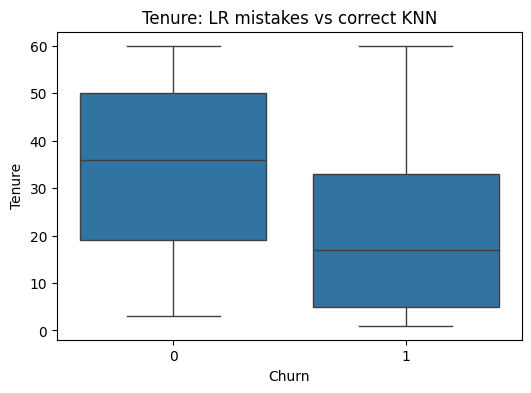

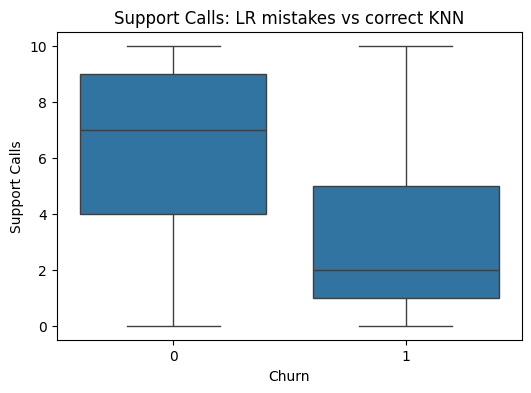

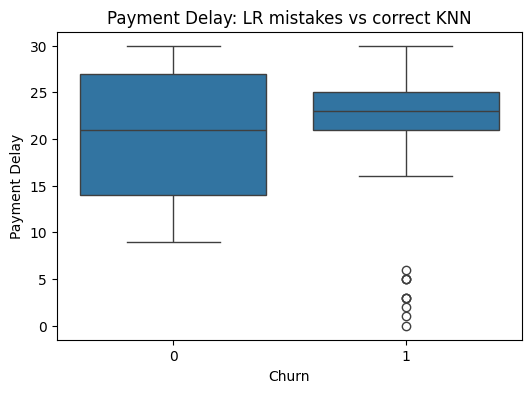

In [ ]:
# LR ошибся, KNN угадал
# Предсказания классов
y_pred_lr = pipe_poly_lr.predict(X_test)

y_pred_knn = pipe_knn.predict(X_test)

# LR ошибся, KNN угадал
mask = (
    (y_pred_lr != y_test)
    &
    (y_pred_knn == y_test)
)

error_cases = X_test[mask]

print("Признаки объектов, где LR ошибается, а KNN верно предсказывает:")

display(error_cases)

# Визуализация
for col in error_cases.columns:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        x=y_test[mask],
        y=error_cases[col]
    )

    plt.title(
        f"{col}: LR mistakes vs correct KNN"
    )

    plt.show()

In [ ]:
results = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Polynomial Logistic Regression',
        'KNN',
        'Random Forest',
        'LightGBM',
        'SVM'
    ],

    'ROC-AUC': [

        roc_auc_lr,

        roc_auc_poly_lr,

        roc_auc_knn,

        roc_auc_rf,

        roc_auc_lgbm,

        roc_auc_svm
    ]
})

results = results.sort_values(
    by='ROC-AUC',
    ascending=False
)

display(results)

,Model,ROC-AUC
4,LightGBM,0.931289
2,KNN,0.907125
3,Random Forest,0.906930
1,Polynomial Logistic Regression,0.893667
0,Logistic Regression,0.880344
5,SVM,0.879560


In [ ]:
# Сохранение Pipeline в PKL
from sklearn.pipeline import Pipeline
import joblib

final_pipeline = Pipeline([
    ('model', lgbm_model)
])

final_pipeline.fit(X_train, y_train)

joblib.dump(
    final_pipeline,
    'churn_pipeline.pkl'
)

print("Pipeline saved successfully")

Pipeline saved successfully


In [ ]:
# Загрузка Pipeline
loaded_pipeline = joblib.load(
    'churn_pipeline.pkl'
)

print("Pipeline loaded successfully")

Pipeline loaded successfully


In [ ]:
# Проверка инференса
sample = X_test.iloc[[0]]

prediction = loaded_pipeline.predict(sample)

probability = loaded_pipeline.predict_proba(sample)

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: [1]
Probability: [[0.00227911 0.99772089]]


In [ ]:
# Test
sample = pd.DataFrame({
    'Tenure': [20],
    'Support Calls': [5],
    'Payment Delay': [10]
})

prediction = loaded_pipeline.predict(sample)

probability = loaded_pipeline.predict_proba(sample)

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: [0]
Probability: [[0.8730839 0.1269161]]


In [ ]:
sample = pd.DataFrame({
    'Tenure': [20],
    'Support Calls': [5],
    'Payment Delay': [10]
})

prediction = loaded_pipeline.predict(sample)
probability = loaded_pipeline.predict_proba(sample)

print("Prediction:", prediction[0])
print("Probability:", probability[0][1])

Prediction: 0
Probability: 0.12691610104552536
